Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union


Warning message:
“`graph()` was deprecated in igraph 2.1.0.
ℹ Please use `make_graph()` instead.”


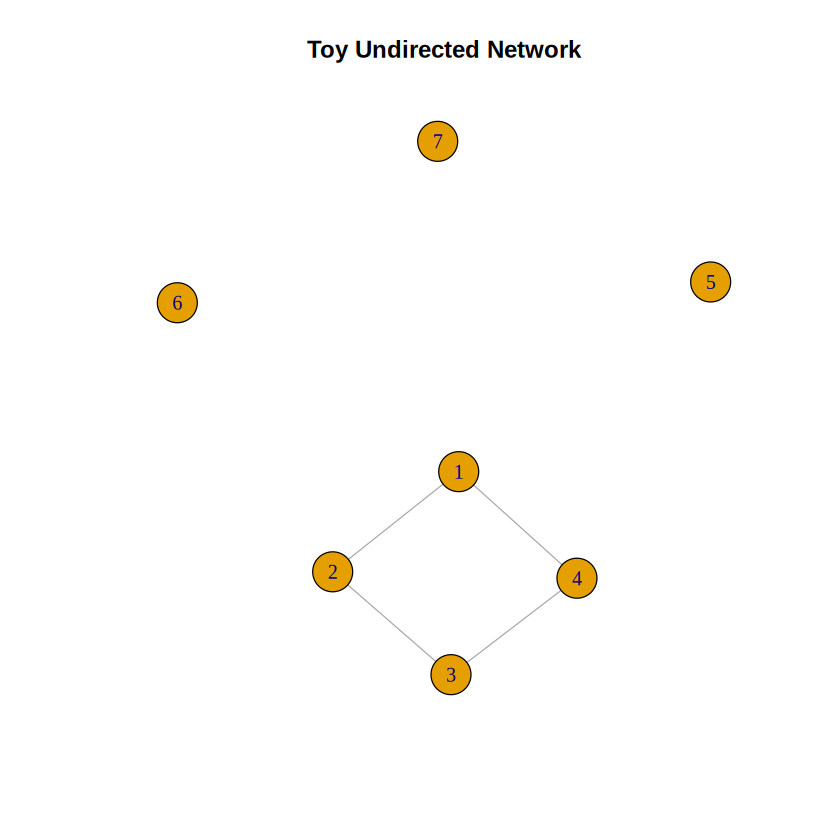


--- Degree (all/in/out) ---
 Amy  Ram   Li Kate 
   3    2    4    1 
 Amy  Ram   Li Kate 
   1    1    3    0 
 Amy  Ram   Li Kate 
   2    1    1    1 

Diameter: 2 
Edge density (built-in): 0.4166667 
Edge density (manual check): 0.4166667 
Reciprocity: 0.4 

--- Closeness centrality ---
      Amy       Ram        Li      Kate 
0.2500000 0.2500000 0.3333333 0.2000000 

--- Betweenness centrality (nodes) ---
 Amy  Ram   Li Kate 
   2    0    3    0 

--- Edge betweenness ---
[1] 3 2 5 1 3


Warning message:
“`graph.data.frame()` was deprecated in igraph 2.0.0.
ℹ Please use `graph_from_data_frame()` instead.”


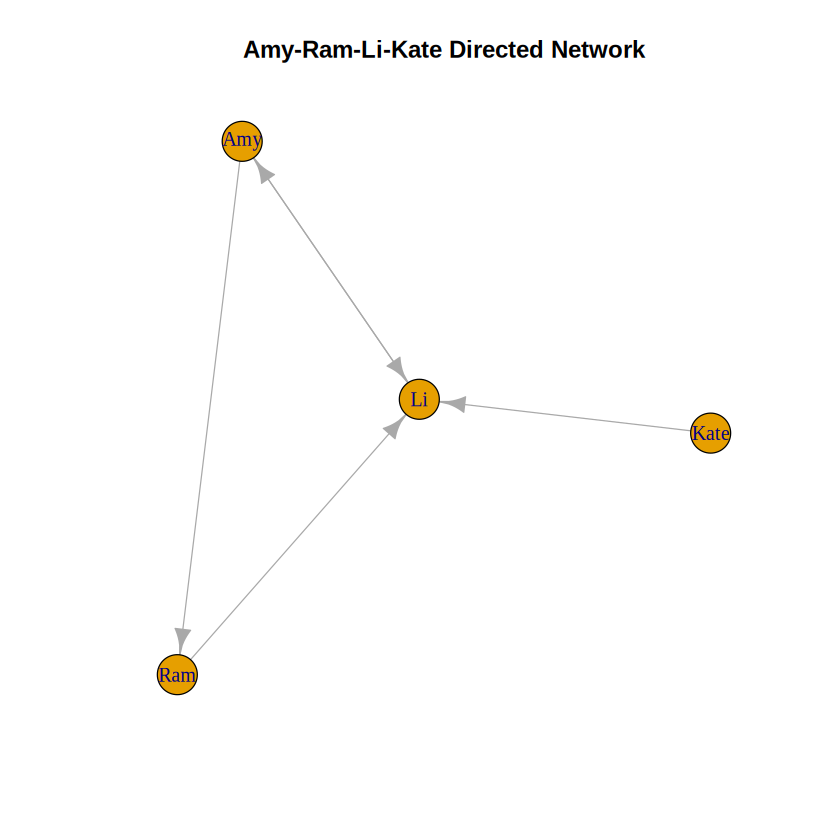

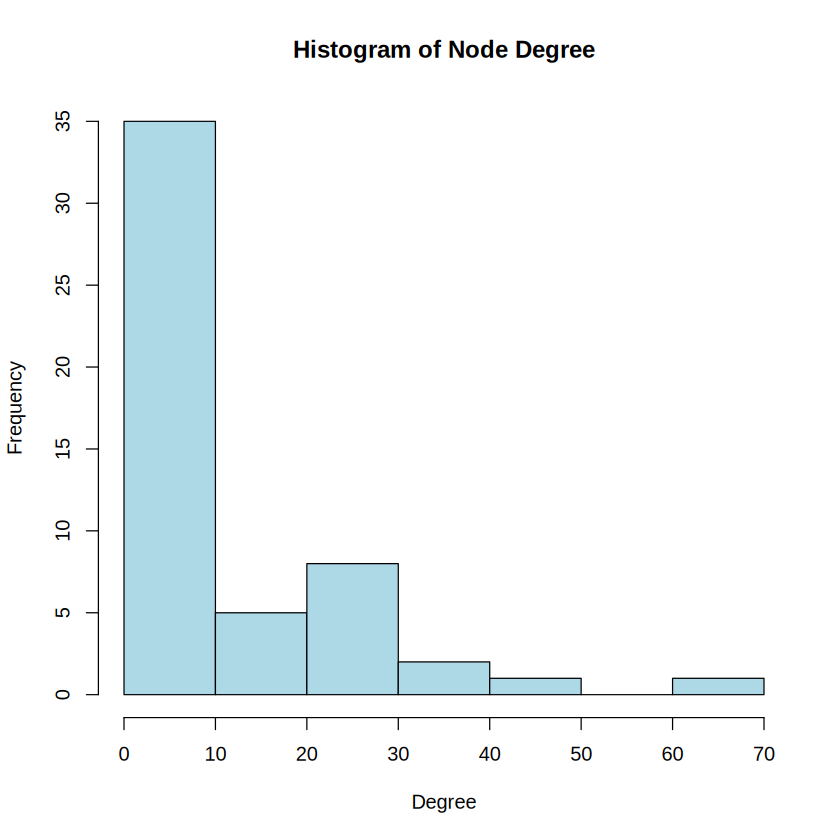

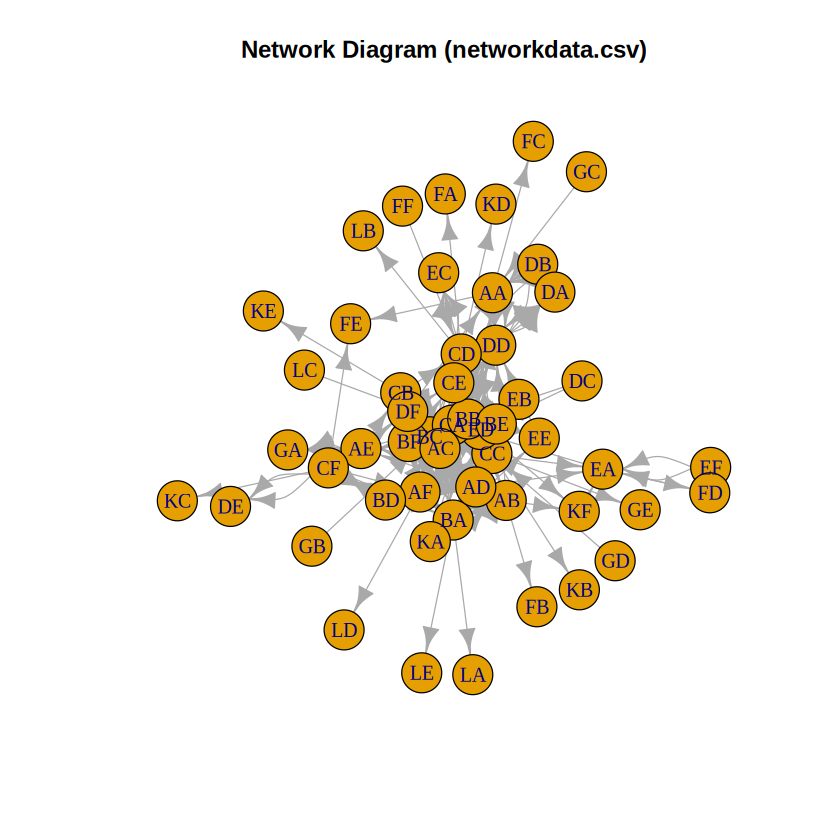

Warning message:
“`hub_score()` was deprecated in igraph 2.0.3.
ℹ Please use `hits_scores()` instead.”
Warning message:
“`authority.score()` was deprecated in igraph 2.0.0.
ℹ Please use `hits_scores()` instead.”


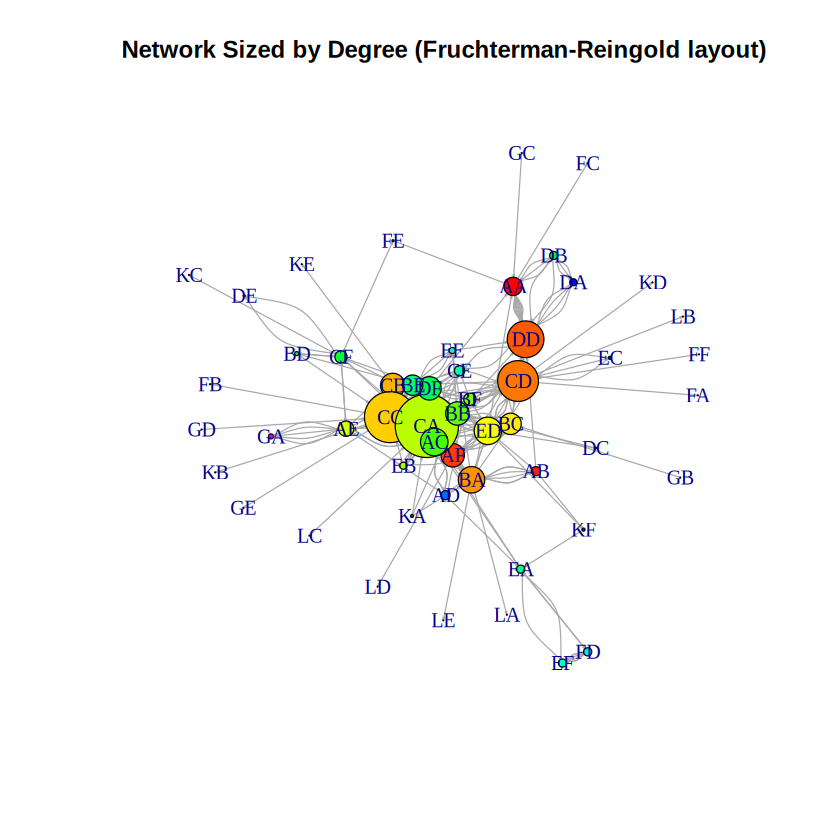


Top 5 Hubs:
       CC        CB        CD        BC        BE 
1.0000000 0.7145888 0.2350165 0.2321828 0.2195271 

Top 5 Authorities:
       CA        DF        DD        CC        BE 
1.0000000 0.1925650 0.1409698 0.1121941 0.1095155 


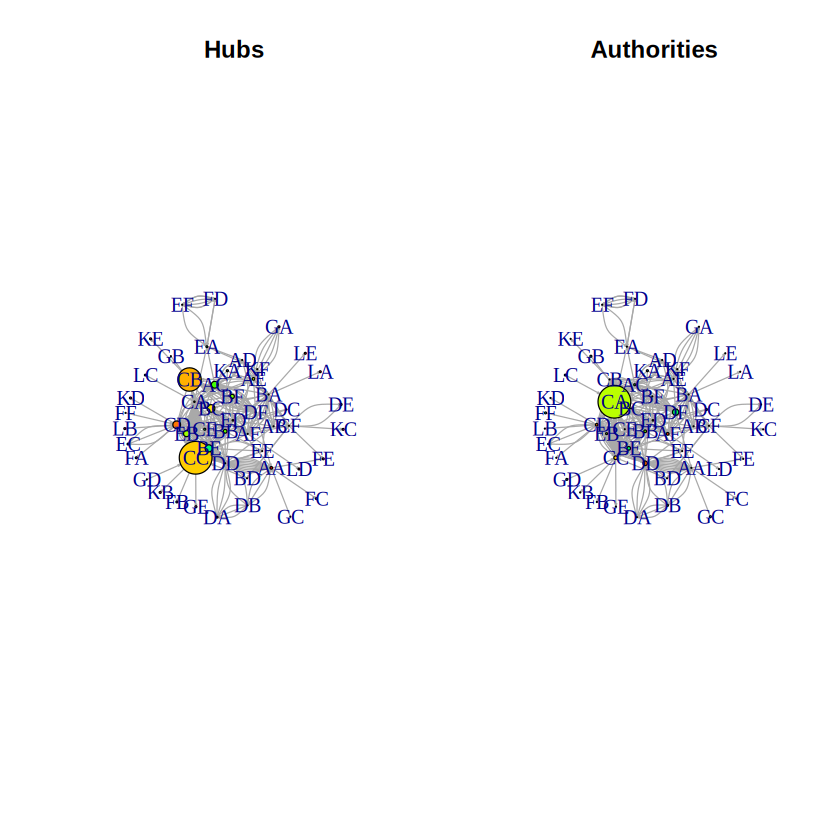


Number of communities detected: 26 
Modularity score: 0.3513853 

================= INTERPRETATION =================
1. The imported network (networkdata.csv) has 52 nodes and 290 edges.
2. Node 'CA' has the highest overall degree,
   i.e. it is the most directly connected individual/entity.
3. Node 'CC' scores highest as a HUB, meaning it
   points to many well-connected (authoritative) nodes.
4. Node 'CA' scores highest as an AUTHORITY, meaning
   many hub nodes point to it, indicating it is a trusted/important entity.
5. Community detection (edge-betweenness) found 26 communities
   with a modularity of 0.351 , indicating how clearly the network
   splits into distinct, tightly-knit sub-groups.


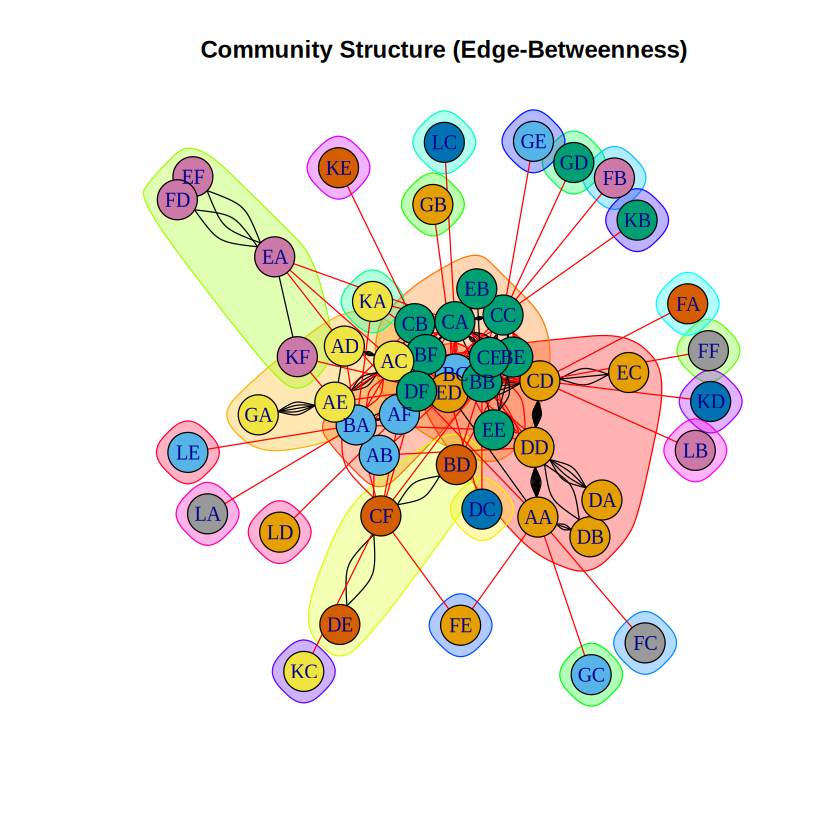

In [5]:
if (!("igraph" %in% rownames(installed.packages()))) {
  install.packages("igraph")
}
library(igraph)

g <- graph(c(1, 2, 2, 3, 3, 4, 4, 1),
           directed = F,
           n = 7)

plot(g, main = "Toy Undirected Network")

g1 <- graph(c("Amy", "Ram", "Ram", "Li", "Li", "Amy",
              "Amy", "Li", "Kate", "Li"),
            directed = T)

plot(g1, main = "Amy-Ram-Li-Kate Directed Network")

cat("\n--- Degree (all/in/out) ---\n")
print(degree(g1, mode = 'all'))
print(degree(g1, mode = 'in'))
print(degree(g1, mode = 'out'))

cat("\nDiameter:", diameter(g1, directed = F, weights = NA), "\n")

cat("Edge density (built-in):", edge_density(g1, loops = F), "\n")
cat("Edge density (manual check):",
    ecount(g1) / (vcount(g1) * (vcount(g1) - 1)), "\n")

cat("Reciprocity:", reciprocity(g1), "\n")

cat("\n--- Closeness centrality ---\n")
print(closeness(g1, mode = 'all', weights = NA))

cat("\n--- Betweenness centrality (nodes) ---\n")
print(betweenness(g1, directed = T, weights = NA))

cat("\n--- Edge betweenness ---\n")
print(edge_betweenness(g1, directed = T, weights = NA))

data <- read.csv(
  'https://raw.githubusercontent.com/bkrai/R-files-from-YouTube/main/networkdata.csv',
  header = T
)
y <- data.frame(data$first, data$second)

net <- graph.data.frame(y, directed = T)
V(net)$label  <- V(net)$name
V(net)$degree <- degree(net)

hist(V(net)$degree,
     main = "Histogram of Node Degree",
     xlab = "Degree", col = "lightblue")

plot(net, main = "Network Diagram (networkdata.csv)")


plot(net,
     vertex.color = rainbow(52),
     vertex.size = V(net)$degree * 0.4,
     edge.arrow.size = 0.1,
     layout = layout.fruchterman.reingold,
     main = "Network Sized by Degree (Fruchterman-Reingold layout)")

hs <- hub_score(net)$vector
as <- authority.score(net)$vector

par(mfrow = c(1, 2))
set.seed(123)
plot(net,
     vertex.size = hs * 30,
     main = 'Hubs',
     vertex.color = rainbow(52),
     edge.arrow.size = 0.1,
     layout = layout.kamada.kawai)

plot(net,
     vertex.size = as * 30,
     main = 'Authorities',
     vertex.color = rainbow(52),
     edge.arrow.size = 0.1,
     layout = layout.kamada.kawai)
par(mfrow = c(1, 1))

cat("\nTop 5 Hubs:\n")
print(head(sort(hs, decreasing = TRUE), 5))

cat("\nTop 5 Authorities:\n")
print(head(sort(as, decreasing = TRUE), 5))

net_undirected <- graph.data.frame(y, directed = F)
cnet <- cluster_edge_betweenness(net_undirected)

plot(cnet, net_undirected, main = "Community Structure (Edge-Betweenness)")

cat("\nNumber of communities detected:", length(cnet), "\n")
cat("Modularity score:", modularity(cnet), "\n")

top_degree_node <- V(net)$name[which.max(V(net)$degree)]
top_hub_node    <- names(sort(hs, decreasing = TRUE))[1]
top_auth_node   <- names(sort(as, decreasing = TRUE))[1]

cat("\n================= INTERPRETATION =================\n")
cat("1. The imported network (networkdata.csv) has", vcount(net),
    "nodes and", ecount(net), "edges.\n")
cat("2. Node '", top_degree_node, "' has the highest overall degree,\n", sep = "")
cat("   i.e. it is the most directly connected individual/entity.\n")
cat("3. Node '", top_hub_node, "' scores highest as a HUB, meaning it\n", sep = "")
cat("   points to many well-connected (authoritative) nodes.\n")
cat("4. Node '", top_auth_node, "' scores highest as an AUTHORITY, meaning\n", sep = "")
cat("   many hub nodes point to it, indicating it is a trusted/important entity.\n")
cat("5. Community detection (edge-betweenness) found", length(cnet),
    "communities\n")
cat("   with a modularity of", round(modularity(cnet), 3),
    ", indicating how clearly the network\n")
cat("   splits into distinct, tightly-knit sub-groups.\n")
cat("====================================================\n")